In [1]:
# Import tools for working with file paths and inspecting the environment.
from pathlib import Path
import sys

# Import libraries for spatial data, tables, network analysis, and plotting.
import geopandas as gpd
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
# set the data folder
data_dir = Path("data/tutorial06-data")

# load the street network
roads = gpd.read_file(
    data_dir / "mna_roadways/mna_roadways.shp"
)

# load the Union Square destination
destination = gpd.read_file(
    data_dir / "union_square/union_square.shp"
)

# preview the street network attributes
roads.head()

,OBJECTID,Street,SAFStreetN,FeatureTyp,SegmentTyp,IncExFlag,RB_Layer,NonPed,TrafDir,TrafSrc,...,FromLeft,ToLeft,FromRight,ToRight,Join_ID,L_PD_Servi,R_PD_Servi,TRUCK_ROUT,SHAPE_Leng,geometry
0,92639.0,BATTERY PARK CITY GREENWAY,NaN,0,U,E,N,D,P,DCP,...,0,0,0,0,1013901000000,NaN,NaN,NaN,114.031859,"LINESTRING (979011.441 196843.914, 979120.371 ..."
1,92640.0,BATTERY PLACE,NaN,0,U,NaN,B,NaN,T,DOT,...,50,64,51,63,1063501000000,NaN,NaN,NaN,262.777812,"LINESTRING (979278.645 196555.536, 979295.647 ..."
2,92641.0,BATTERY PLACE,PS 94,0,U,NaN,B,NaN,T,DOT,...,0,0,0,0,10001101000000N,NaN,NaN,NaN,262.777812,"LINESTRING (979278.645 196555.536, 979295.647 ..."
3,92642.0,WEST THAMES STREET,NaN,0,U,NaN,B,NaN,T,DOT,...,300,398,301,399,1478001000000,NaN,NaN,NaN,241.736699,"LINESTRING (979426.49 197387.106, 979218.442 1..."
4,92643.0,1 PLACE,NaN,0,U,NaN,B,NaN,W,DOT,...,0,0,0,0,1248301020000,NaN,NaN,NaN,293.100274,"LINESTRING (979537.962 196418.925, 979278.645 ..."


In [3]:
# inspect the coordinate reference systems
print("Street network:", roads.crs)
print("Destination:", destination.crs)

# inspect the coordinate units used by the street network
print("Street network units:", roads.crs.axis_info[0].unit_name)

Street network: EPSG:2263
Destination: EPSG:2263
Street network units: US survey foot


In [4]:
# use a common projection with coordinates measured in meters
target_crs = "EPSG:32618"

roads = roads.to_crs(target_crs)
destination = destination.to_crs(target_crs)

# confirm that both layers now use the same CRS
print("Street network:", roads.crs)
print("Destination:", destination.crs)

Street network: EPSG:32618
Destination: EPSG:32618


In [7]:
# register the local Roboto font with Matplotlib
from matplotlib import font_manager

font_path = Path(
    "Assignement 03 Spatial Relatedness/data/fonts/Roboto-Light.ttf"
)
font_manager.fontManager.addfont(str(font_path))

# use the registered font for all subsequent plots
roboto_name = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams["font.family"] = roboto_name

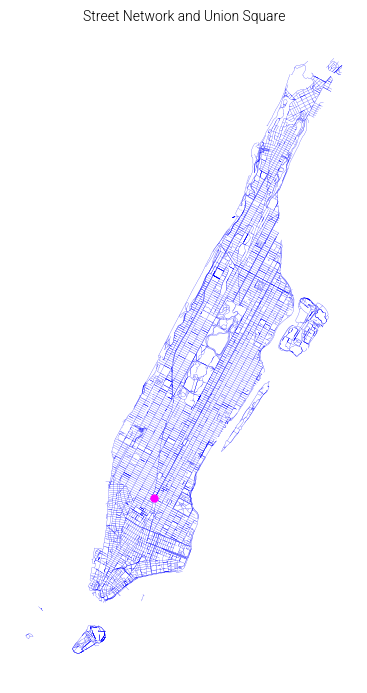

In [12]:
# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# draw the street network in blue
roads.plot(
    ax=ax,
    color="#0000ff",
    linewidth=0.15
)

# highlight Union Square in magenta
destination.plot(
    ax=ax,
    color="#ff00ff",
    markersize=25,
    zorder=3
)

# format the map using the previously configured Roboto font
ax.set_title("Street Network and Union Square", fontsize=10)
ax.set_axis_off()

plt.show()

In [13]:
# list the available street attributes
print(roads.columns.tolist())

# check the geometry types in the street network
print("\nGeometry types:")
print(roads.geom_type.value_counts())

# preview the street attributes
display(roads.head())

['OBJECTID', 'Street', 'SAFStreetN', 'FeatureTyp', 'SegmentTyp', 'IncExFlag', 'RB_Layer', 'NonPed', 'TrafDir', 'TrafSrc', 'SpecAddr', 'FaceCode', 'SeqNum', 'StreetCode', 'SAFStreetC', 'LGC1', 'LGC2', 'LGC3', 'LGC4', 'LGC5', 'LGC6', 'LGC7', 'LGC8', 'LGC9', 'BOE_LGC', 'SegmentID', 'SegCount', 'LocStatus', 'LZip', 'RZip', 'LBoro', 'RBoro', 'L_CD', 'R_CD', 'LATOMICPOL', 'RATOMICPOL', 'LCT2020', 'LCT2020Suf', 'RCT2020', 'RCT2020Suf', 'LCB2020', 'LCB2020Suf', 'RCB2020', 'RCB2020Suf', 'LCT2010', 'LCT2010Suf', 'RCT2010', 'RCT2010Suf', 'LCB2010', 'LCB2010Suf', 'RCB2010', 'RCB2010Suf', 'LCT2000', 'LCT2000Suf', 'RCT2000', 'RCT2000Suf', 'LCB2000', 'LCB2000Suf', 'RCB2000', 'RCB2000Suf', 'LCT1990', 'LCT1990Suf', 'RCT1990', 'RCT1990Suf', 'LAssmDist', 'LElectDist', 'RAssmDist', 'RElectDist', 'SplitElect', 'LSchlDist', 'RSchlDist', 'SplitSchl', 'LSubSect', 'RSubSect', 'SanDistInd', 'MapFrom', 'MapTo', 'BoroBndry', 'MH_RI_Flag', 'XFrom', 'YFrom', 'XTo', 'YTo', 'ArcCenterX', 'ArcCenterY', 'CurveFlag', 'R

,OBJECTID,Street,SAFStreetN,FeatureTyp,SegmentTyp,IncExFlag,RB_Layer,NonPed,TrafDir,TrafSrc,...,FromLeft,ToLeft,FromRight,ToRight,Join_ID,L_PD_Servi,R_PD_Servi,TRUCK_ROUT,SHAPE_Leng,geometry
0,92639.0,BATTERY PARK CITY GREENWAY,NaN,0,U,E,N,D,P,DCP,...,0,0,0,0,1013901000000,NaN,NaN,NaN,114.031859,"LINESTRING (582877.448 4506691.122, 582910.755..."
1,92640.0,BATTERY PLACE,NaN,0,U,NaN,B,NaN,T,DOT,...,50,64,51,63,1063501000000,NaN,NaN,NaN,262.777812,"LINESTRING (582959.861 4506604.184, 582964.822..."
2,92641.0,BATTERY PLACE,PS 94,0,U,NaN,B,NaN,T,DOT,...,0,0,0,0,10001101000000N,NaN,NaN,NaN,262.777812,"LINESTRING (582959.861 4506604.184, 582964.822..."
3,92642.0,WEST THAMES STREET,NaN,0,U,NaN,B,NaN,T,DOT,...,300,398,301,399,1478001000000,NaN,NaN,NaN,241.736699,"LINESTRING (583002.023 4506858.063, 582938.207..."
4,92643.0,1 PLACE,NaN,0,U,NaN,B,NaN,W,DOT,...,0,0,0,0,1248301020000,NaN,NaN,NaN,293.100274,"LINESTRING (583039.345 4506563.46, 582959.861 ..."


In [14]:
# keep streets with non-empty geometries
roads = roads.loc[
    roads.geometry.notna()
    & ~roads.geometry.is_empty
].copy()

# split multipart geometries into individual street segments
roads = roads.explode(index_parts=False).reset_index(drop=True)

# calculate segment lengths in meters using our projected CRS
roads["length_m"] = roads.geometry.length

# inspect street connections, lengths, and bicycle lane attributes
roads[
    ["Street", "NodeIDFrom", "NodeIDTo", "length_m", "BikeLane"]
].head()

,Street,NodeIDFrom,NodeIDTo,length_m,BikeLane
0,BATTERY PARK CITY GREENWAY,0012339,0012375,34.746075,1
1,BATTERY PLACE,0012377,0012380,80.069584,NaN
2,BATTERY PLACE,0012377,0012380,80.069584,NaN
3,WEST THAMES STREET,0012398,0012394,73.658388,NaN
4,1 PLACE,0095550,0012377,89.309125,NaN


In [15]:
# create an undirected network that preserves parallel street segments
G = nx.MultiGraph()

# add each street segment to the network
for index, row in roads.iterrows():

    # skip segments without valid endpoint identifiers
    if pd.isna(row["NodeIDFrom"]) or pd.isna(row["NodeIDTo"]):
        continue

    from_node = str(row["NodeIDFrom"]).strip()
    to_node = str(row["NodeIDTo"]).strip()

    if not from_node or not to_node:
        continue

    # store segment length and its corresponding row in the street layer
    G.add_edge(
        from_node,
        to_node,
        key=index,
        length_m=row["length_m"],
        road_index=index
    )

# inspect the size and connectivity of the network
print("Nodes:", G.number_of_nodes())
print("Street segments:", G.number_of_edges())
print("Connected components:", nx.number_connected_components(G))

Nodes: 13861
Street segments: 23305
Connected components: 68


In [16]:
# define a starting point near Columbia's Broadway entrance
# coordinates are provided in longitude, latitude order
start = gpd.GeoDataFrame(
    {"name": ["Columbia University"]},
    geometry=gpd.points_from_xy(
        [-73.9640],
        [40.8075]
    ),
    crs="EPSG:4326"
)

# project the starting point to match the street network
start = start.to_crs(roads.crs)

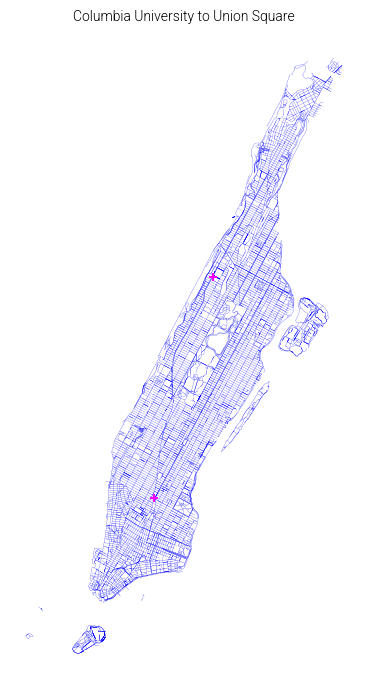

In [22]:
# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# draw the street network in blue
roads.plot(ax=ax, color="#0000ff", linewidth=0.15)

# draw the starting point and destination in magenta
start.plot(
    ax=ax,
    color="#ff00ff",
    marker="+",
    markersize=30,
    zorder=3
)
destination.plot(
    ax=ax,
    color="#ff00ff",
    marker="+",
    markersize=30,
    zorder=3
)

# format the map
ax.set_title("Columbia University to Union Square", fontsize=10)
ax.set_axis_off()

plt.show()

In [23]:
# assign coordinates to network nodes using street segment endpoints
for index, row in roads.iterrows():
    from_node = str(row["NodeIDFrom"]).strip()
    to_node = str(row["NodeIDTo"]).strip()

    # read the first and last coordinates of each street segment
    coordinates = list(row.geometry.coords)

    if from_node in G:
        G.nodes[from_node]["pos"] = coordinates[0][:2]

    if to_node in G:
        G.nodes[to_node]["pos"] = coordinates[-1][:2]

# create a spatial layer of network nodes
node_ids = [node for node, data in G.nodes(data=True) if "pos" in data]
positions = [G.nodes[node]["pos"] for node in node_ids]

nodes = gpd.GeoDataFrame(
    {"node_id": node_ids},
    geometry=gpd.points_from_xy(
        [position[0] for position in positions],
        [position[1] for position in positions]
    ),
    crs=roads.crs
)

# measure the distance from every node to each endpoint
start_distances = nodes.distance(start.geometry.iloc[0])
destination_distances = nodes.distance(destination.geometry.iloc[0])

# identify the nearest node to each endpoint
start_index = start_distances.idxmin()
destination_index = destination_distances.idxmin()

start_node = nodes.loc[start_index, "node_id"]
destination_node = nodes.loc[destination_index, "node_id"]

# inspect how far each original point lies from its selected node
print("Start offset (meters):", round(start_distances.loc[start_index], 1))
print(
    "Destination offset (meters):",
    round(destination_distances.loc[destination_index], 1)
)

# check whether a route exists between the selected nodes
print("Route available:", nx.has_path(G, start_node, destination_node))

Start offset (meters): 13.0
Destination offset (meters): 4.5
Route available: True


In [24]:
# calculate the shortest path using segment lengths in meters
shortest_nodes = nx.shortest_path(
    G,
    source=start_node,
    target=destination_node,
    weight="length_m"
)

# retrieve the shortest street segment between each pair of route nodes
shortest_indices = []

for from_node, to_node in zip(shortest_nodes[:-1], shortest_nodes[1:]):
    parallel_edges = G[from_node][to_node]

    # select the shortest edge when multiple segments connect the same nodes
    best_edge = min(
        parallel_edges.values(),
        key=lambda edge: edge["length_m"]
    )

    shortest_indices.append(best_edge["road_index"])

# create a spatial layer containing the route segments
shortest_route = roads.loc[shortest_indices].copy()

# calculate the total route length
shortest_length_km = shortest_route["length_m"].sum() / 1000

print(f"Shortest route: {shortest_length_km:.2f} km")

Shortest route: 8.70 km


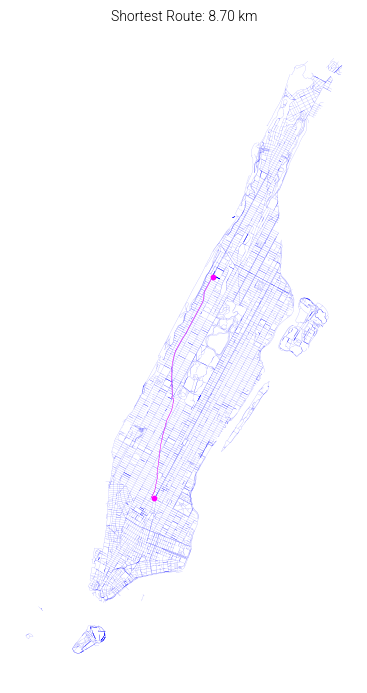

In [28]:
# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# draw the street network in blue
roads.plot(
    ax=ax,
    color="#0000ff",
    linewidth=0.15,
    alpha=0.4
)

# highlight the shortest route in magenta
shortest_route.plot(
    ax=ax,
    color="#ff00ff",
    linewidth=0.35,
    zorder=2
)

# mark the selected network endpoints in magenta
nodes.loc[[start_index, destination_index]].plot(
    ax=ax,
    color="#ff00ff",
    markersize=10,
    zorder=3
)

# format the map
ax.set_title(f"Shortest Route: {shortest_length_km:.2f} km", fontsize=10)
ax.set_axis_off()

plt.show()

In [29]:
# standardize bicycle lane codes and treat blank values as missing
bike_codes = roads["BikeLane"].astype("string").str.strip()
bike_codes = bike_codes.replace("", pd.NA)

# assign a default preference to streets without bicycle lanes
roads["bikePref"] = 1

# give other non-empty bicycle lane codes a preference of 2
roads.loc[bike_codes.notna(), "bikePref"] = 2

# assign the tutorial's preferences to the three main lane types
roads.loc[bike_codes == "1", "bikePref"] = 7
roads.loc[bike_codes == "2", "bikePref"] = 5
roads.loc[bike_codes == "3", "bikePref"] = 3

# calculate the routing cost: higher preference reduces the cost
roads["bike_cost"] = roads["length_m"] / roads["bikePref"]

# inspect the bicycle preferences and resulting costs
roads[
    ["Street", "BikeLane", "length_m", "bikePref", "bike_cost"]
].head()

,Street,BikeLane,length_m,bikePref,bike_cost
0,BATTERY PARK CITY GREENWAY,1,34.746075,7,4.963725
1,BATTERY PLACE,NaN,80.069584,1,80.069584
2,BATTERY PLACE,NaN,80.069584,1,80.069584
3,WEST THAMES STREET,NaN,73.658388,1,73.658388
4,1 PLACE,NaN,89.309125,1,89.309125


In [39]:
# add bicycle preference costs to the existing network edges
for from_node, to_node, key, edge in G.edges(keys=True, data=True):
    road_index = edge["road_index"]
    edge["bike_cost"] = roads.loc[road_index, "bike_cost"]

# calculate the path that minimizes the bicycle preference cost
bike_nodes = nx.shortest_path(
    G,
    source=start_node,
    target=destination_node,
    weight="bike_cost"
)

# retrieve the preferred street segment between each pair of route nodes
bike_indices = []

for from_node, to_node in zip(bike_nodes[:-1], bike_nodes[1:]):
    parallel_edges = G[from_node][to_node]

    # select the edge with the lowest bicycle cost
    best_edge = min(
        parallel_edges.values(),
        key=lambda edge: edge["bike_cost"]
    )

    bike_indices.append(best_edge["road_index"])

# create a spatial layer containing the bicycle-preferred route
bike_route = roads.loc[bike_indices].copy()

# compare the physical lengths of the two routes
bike_length_km = bike_route["length_m"].sum() / 1000

print(f"Shortest route: {shortest_length_km:.2f} km")
print(f"Bicycle-preferred route: {bike_length_km:.2f} km")

Shortest route: 8.70 km
Bicycle-preferred route: 9.78 km


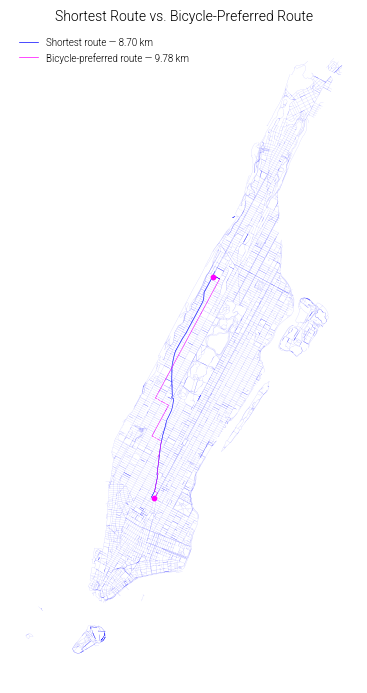

In [47]:
# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# draw the street network in blue
roads.plot(
    ax=ax,
    color="#0000ff",
    linewidth=0.15,
    alpha=0.25
)

# draw the shortest route as a wider blue line
shortest_route.plot(
    ax=ax,
    color="#0000ff",
    linewidth=0.4,
    zorder=2
)

# draw the bicycle-preferred route as a dashed magenta line
bike_route.plot(
    ax=ax,
    color="#ff00ff",
    linewidth=0.4,
    linestyle="--",
    zorder=3
)

# mark the selected network endpoints in magenta
nodes.loc[[start_index, destination_index]].plot(
    ax=ax,
    color="#ff00ff",
    markersize=10,
    zorder=4
)

# create legend entries matching the route styles
from matplotlib.lines import Line2D

legend_items = [
    Line2D(
        [0], [0],
        color="#0000ff",
        linewidth=0.5,
        label=f"Shortest route — {shortest_length_km:.2f} km"
    ),
    Line2D(
        [0], [0],
        color="#ff00ff",
        linewidth=0.5,
        label=f"Bicycle-preferred route — {bike_length_km:.2f} km"
    )
]

# place a smaller legend below the title on the left
ax.legend(
    handles=legend_items,
    loc="upper left",
    fontsize=7,
    frameon=False
)

# format the map
ax.set_title("Shortest Route vs. Bicycle-Preferred Route", fontsize=10)
ax.set_axis_off()

plt.show()

In [48]:
# inspect the posted speed values, including missing entries
print("Posted speed values:")
print(roads["POSTED_SPE"].value_counts(dropna=False))

# convert speed values to numbers
# blank or non-numeric entries become missing values
roads["posted_speed"] = pd.to_numeric(
    roads["POSTED_SPE"],
    errors="coerce"
)

# inspect the numeric speed distribution
print("\nNumeric speed summary:")
print(roads["posted_speed"].describe())

# preview street names and speed values
roads[
    ["Street", "POSTED_SPE", "posted_speed"]
].head()

Posted speed values:
POSTED_SPE
25     16434
NaN     5852
20       873
30       116
35        22
50         4
40         4
Name: count, dtype: int64

Numeric speed summary:
count    17453.000000
mean        24.804905
std          1.303671
min         20.000000
25%         25.000000
50%         25.000000
75%         25.000000
max         50.000000
Name: posted_speed, dtype: float64


,Street,POSTED_SPE,posted_speed
0,BATTERY PARK CITY GREENWAY,NaN,NaN
1,BATTERY PLACE,25,25.0
2,BATTERY PLACE,25,25.0
3,WEST THAMES STREET,25,25.0
4,1 PLACE,25,25.0


In [49]:
# identify valid positive speed limits
valid_speeds = roads.loc[
    roads["posted_speed"] > 0,
    "posted_speed"
]

# check that the dataset contains usable speed limits
if valid_speeds.empty:
    raise ValueError("No valid positive speed limits were found.")

# use the median positive speed for missing or non-positive values
default_speed = valid_speeds.median()

roads["routing_speed"] = roads["posted_speed"].where(
    roads["posted_speed"] > 0,
    default_speed
)

# calculate a preference cost combining distance and posted speed
# higher speed limits increase the cost per meter
roads["speed_cost"] = (
    roads["length_m"]
    * roads["routing_speed"]
    / default_speed
)

# inspect the resulting costs
print("Default posted speed:", default_speed)

roads[
    ["Street", "posted_speed", "routing_speed", "speed_cost"]
].head()

Default posted speed: 25.0


,Street,posted_speed,routing_speed,speed_cost
0,BATTERY PARK CITY GREENWAY,NaN,25.0,34.746075
1,BATTERY PLACE,25.0,25.0,80.069584
2,BATTERY PLACE,25.0,25.0,80.069584
3,WEST THAMES STREET,25.0,25.0,73.658388
4,1 PLACE,25.0,25.0,89.309125


In [50]:
# add the posted-speed preference cost to each network edge
for from_node, to_node, key, edge in G.edges(keys=True, data=True):
    road_index = edge["road_index"]
    edge["speed_cost"] = roads.loc[road_index, "speed_cost"]

# calculate the path with the lowest total posted-speed preference cost
speed_nodes = nx.shortest_path(
    G,
    source=start_node,
    target=destination_node,
    weight="speed_cost"
)

# retrieve the preferred street segment between each pair of route nodes
speed_indices = []

for from_node, to_node in zip(speed_nodes[:-1], speed_nodes[1:]):
    parallel_edges = G[from_node][to_node]

    # select the edge with the lowest speed preference cost
    best_edge = min(
        parallel_edges.values(),
        key=lambda edge: edge["speed_cost"]
    )

    speed_indices.append(best_edge["road_index"])

# create a spatial layer containing the third route
speed_route = roads.loc[speed_indices].copy()

# calculate the physical length of the third route
speed_length_km = speed_route["length_m"].sum() / 1000

# compare the lengths of all three routes
print(f"Shortest route: {shortest_length_km:.2f} km")
print(f"Bicycle-preferred route: {bike_length_km:.2f} km")
print(f"Lower-speed-preferred route: {speed_length_km:.2f} km")

Shortest route: 8.70 km
Bicycle-preferred route: 9.78 km
Lower-speed-preferred route: 8.70 km


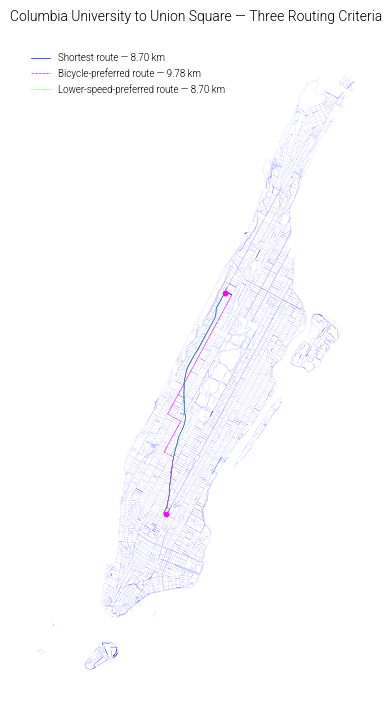

In [54]:
# import tools for creating custom legend entries
from matplotlib.lines import Line2D

# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# draw the street network in blue
roads.plot(
    ax=ax,
    color="#0000ff",
    linewidth=0.15,
    alpha=0.25
)

# draw the shortest route in blue
shortest_route.plot(
    ax=ax,
    color="#0000ff",
    linewidth=0.4,
    zorder=2
)

# draw the bicycle-preferred route as a dashed magenta line
bike_route.plot(
    ax=ax,
    color="#ff00ff",
    linewidth=0.4,
    linestyle="--",
    zorder=3
)

# draw the lower-speed-preferred route as a dotted black line
speed_route.plot(
    ax=ax,
    color="#00ff00",
    linewidth=0.4,
    linestyle=":",
    zorder=4
)

# mark the selected network endpoints in magenta
nodes.loc[[start_index, destination_index]].plot(
    ax=ax,
    color="#ff00ff",
    markersize=10,
    zorder=5
)

# create legend entries matching the route colors and line styles
legend_items = [
    Line2D(
        [0], [0],
        color="#0000ff",
        linewidth=0.5,
        label=f"Shortest route — {shortest_length_km:.2f} km"
    ),
    Line2D(
        [0], [0],
        color="#ff00ff",
        linewidth=0.5,
        linestyle="--",
        label=f"Bicycle-preferred route — {bike_length_km:.2f} km"
    ),
    Line2D(
        [0], [0],
        color="#00ff00",
        linewidth=0.5,
        linestyle=":",
        label=f"Lower-speed-preferred route — {speed_length_km:.2f} km"
    )
]

# place the legend below the title on the left
ax.legend(
    handles=legend_items,
    loc="upper left",
    fontsize=7,
    frameon=False
)

# format the map using the previously configured Roboto font
ax.set_title(
    "Columbia University to Union Square — Three Routing Criteria",
    fontsize=10
)
ax.set_axis_off()

plt.show()

In [58]:
# check whether the two routes use the same street segments
same_segments = set(shortest_indices) == set(speed_indices)
print("Same street segments:", same_segments)

# inspect current speed values for the shortest route
print("\nShortest route:")
print(
    roads.loc[shortest_indices, "routing_speed"].value_counts()
)

# inspect current speed values for the lower-speed-preferred route
print("\nLower-speed-preferred route:")
print(
    roads.loc[speed_indices, "routing_speed"].value_counts()
)

Same street segments: True

Shortest route:
routing_speed
25.0    134
Name: count, dtype: int64

Lower-speed-preferred route:
routing_speed
25.0    134
Name: count, dtype: int64


In [59]:
# inspect truck route codes across the street network
print("Truck route codes:")
print(roads["TRUCK_ROUT"].value_counts(dropna=False))

# inspect truck route codes along the shortest route
print("\nTruck route codes along the shortest route:")
print(
    roads.loc[shortest_indices, "TRUCK_ROUT"]
    .value_counts(dropna=False)
)

# preview street names and their truck route codes
roads[["Street", "TRUCK_ROUT"]].head()

Truck route codes:
TRUCK_ROUT
NaN    18699
2       4079
3        527
Name: count, dtype: int64

Truck route codes along the shortest route:
TRUCK_ROUT
2      99
NaN    35
Name: count, dtype: int64


,Street,TRUCK_ROUT
0,BATTERY PARK CITY GREENWAY,NaN
1,BATTERY PLACE,NaN
2,BATTERY PLACE,NaN
3,WEST THAMES STREET,NaN
4,1 PLACE,NaN


In [60]:
# standardize the truck route codes
truck_codes = roads["TRUCK_ROUT"].astype("string").str.strip()

# identify local and through truck routes
roads["is_truck_route"] = truck_codes.isin(["2", "3"])

# assign a default multiplier to all street segments
roads["truck_penalty"] = 1.0

# increase the cost of designated truck routes
roads.loc[roads["is_truck_route"], "truck_penalty"] = 5.0

# combine physical distance with the truck route penalty
roads["truck_cost"] = (
    roads["length_m"] * roads["truck_penalty"]
)

# inspect the resulting costs
roads[
    ["Street", "TRUCK_ROUT", "length_m", "truck_penalty", "truck_cost"]
].head()

,Street,TRUCK_ROUT,length_m,truck_penalty,truck_cost
0,BATTERY PARK CITY GREENWAY,NaN,34.746075,1.0,34.746075
1,BATTERY PLACE,NaN,80.069584,1.0,80.069584
2,BATTERY PLACE,NaN,80.069584,1.0,80.069584
3,WEST THAMES STREET,NaN,73.658388,1.0,73.658388
4,1 PLACE,NaN,89.309125,1.0,89.309125


In [62]:
# add truck route costs to the network edges
for from_node, to_node, key, edge in G.edges(keys=True, data=True):
    road_index = edge["road_index"]
    edge["truck_cost"] = roads.loc[road_index, "truck_cost"]

# calculate the path with the lowest total truck route cost
truck_nodes = nx.shortest_path(
    G,
    source=start_node,
    target=destination_node,
    weight="truck_cost"
)

# retrieve the preferred segment between each pair of route nodes
truck_indices = []

for from_node, to_node in zip(truck_nodes[:-1], truck_nodes[1:]):
    parallel_edges = G[from_node][to_node]

    # select the edge with the lowest truck route cost
    best_edge = min(
        parallel_edges.values(),
        key=lambda edge: edge["truck_cost"]
    )

    truck_indices.append(best_edge["road_index"])

# create a spatial layer containing the route
truck_route = roads.loc[truck_indices].copy()

# calculate the physical route length
truck_length_km = truck_route["length_m"].sum() / 1000

# compare the new route with the shortest route
print(f"Shortest route: {shortest_length_km:.2f} km")
print(f"Truck-avoidance route: {truck_length_km:.2f} km")
print(
    "Same street segments:",
    set(shortest_indices) == set(truck_indices)
)

# compare the distance traveled on designated truck routes
for name, indices in [
    ("Shortest", shortest_indices),
    ("Truck-avoidance", truck_indices)
]:
    route = roads.loc[indices]
    truck_distance_km = route.loc[
        route["is_truck_route"], "length_m"
    ].sum() / 1000

    print(f"{name} — distance on truck routes: {truck_distance_km:.2f} km")

Shortest route: 8.70 km
Truck-avoidance route: 9.64 km
Same street segments: False
Shortest — distance on truck routes: 6.10 km
Truck-avoidance — distance on truck routes: 0.16 km


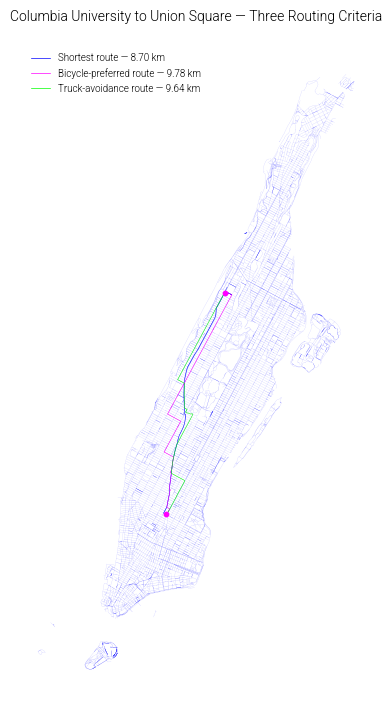

In [65]:
# import tools for creating custom legend entries
from matplotlib.lines import Line2D

# create the figure
fig, ax = plt.subplots(figsize=(11, 8.5))

# draw the street network in blue
roads.plot(
    ax=ax,
    color="#0000ff",
    linewidth=0.15,
    alpha=0.25
)

# draw the shortest route in blue
shortest_route.plot(
    ax=ax,
    color="#0000ff",
    linewidth=0.4,
    zorder=2
)

# draw the bicycle-preferred route as a dashed magenta line
bike_route.plot(
    ax=ax,
    color="#ff00ff",
    linewidth=0.4,
    zorder=3
)

# draw the truck-avoidance route as a dotted black line
truck_route.plot(
    ax=ax,
    color="#00ff00",
    linewidth=0.4,
    zorder=4
)

# mark the selected network endpoints in magenta
nodes.loc[[start_index, destination_index]].plot(
    ax=ax,
    color="#ff00ff",
    markersize=10,
    zorder=5
)

# create legend entries matching the route colors and line styles
legend_items = [
    Line2D(
        [0], [0],
        color="#0000ff",
        linewidth=0.5,
        label=f"Shortest route — {shortest_length_km:.2f} km"
    ),
    Line2D(
        [0], [0],
        color="#ff00ff",
        linewidth=0.5,
        label=f"Bicycle-preferred route — {bike_length_km:.2f} km"
    ),
    Line2D(
        [0], [0],
        color="#00ff00",
        linewidth=0.5,
        label=f"Truck-avoidance route — {truck_length_km:.2f} km"
    )
]

# place the legend below the title on the left
ax.legend(
    handles=legend_items,
    loc="upper left",
    fontsize=7,
    frameon=False
)

# format the map using the previously configured Roboto font
ax.set_title(
    "Columbia University to Union Square — Three Routing Criteria",
    fontsize=10
)
ax.set_axis_off()

plt.show()

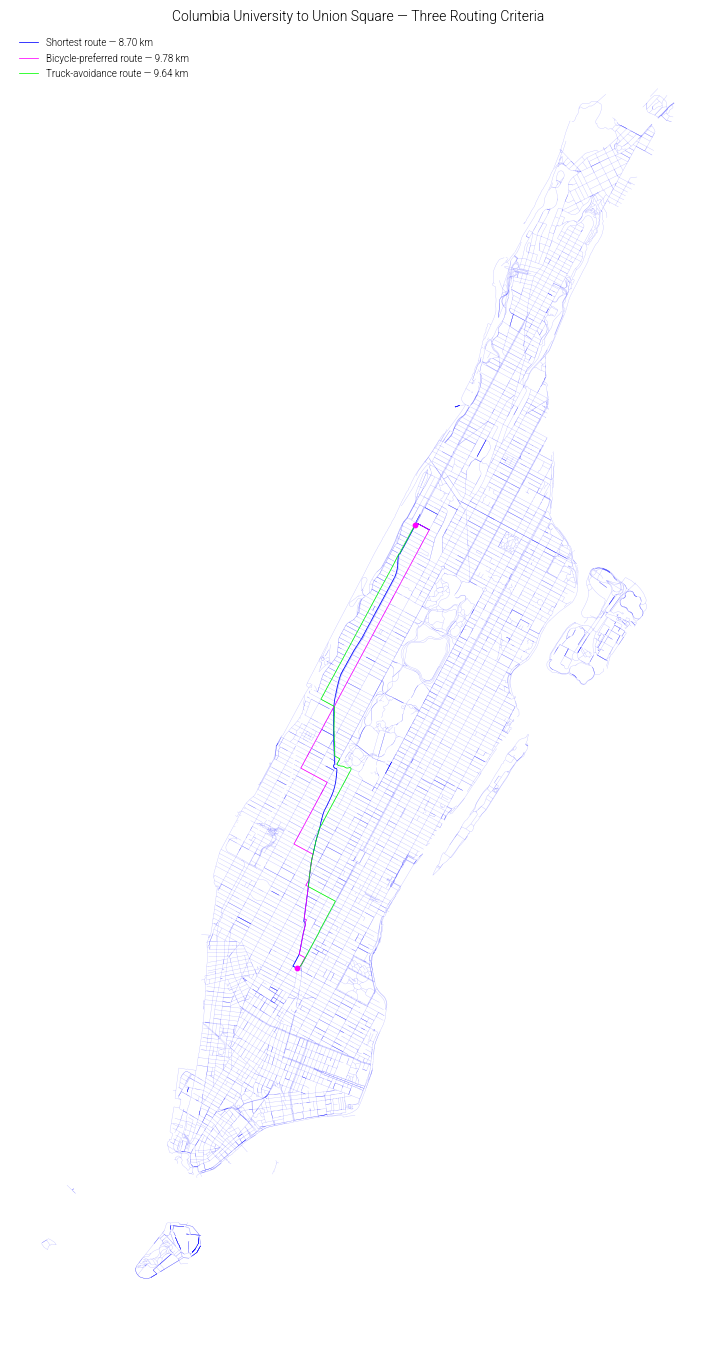

Saved: /Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/tutorial06_map.pdf


In [72]:
# import tools for file paths and custom legend entries
from pathlib import Path
from matplotlib.lines import Line2D

# create an 11-by-17-inch portrait figure
fig, ax = plt.subplots(figsize=(11, 17))

# draw the street network in blue
roads.plot(
    ax=ax,
    color="#0000ff",
    linewidth=0.25,
    alpha=0.25
)

# draw the shortest route in blue
shortest_route.plot(
    ax=ax,
    color="#0000ff",
    linewidth=0.55,
    zorder=2
)

# draw the bicycle-preferred route in magenta
bike_route.plot(
    ax=ax,
    color="#ff00ff",
    linewidth=0.55,
    zorder=3
)

# draw the truck-avoidance route in black
truck_route.plot(
    ax=ax,
    color="#00ff00",
    linewidth=0.55,
    zorder=4
)

# mark the selected network endpoints in magenta
nodes.loc[[start_index, destination_index]].plot(
    ax=ax,
    color="#ff00ff",
    markersize=10,
    zorder=5
)

# create legend entries matching the route styles
legend_items = [
    Line2D(
        [0], [0],
        color="#0000ff",
        linewidth=0.55,
        label=f"Shortest route — {shortest_length_km:.2f} km"
    ),
    Line2D(
        [0], [0],
        color="#ff00ff",
        linewidth=0.55,
        label=f"Bicycle-preferred route — {bike_length_km:.2f} km"
    ),
    Line2D(
        [0], [0],
        color="#00ff00",
        linewidth=0.55,
        label=f"Truck-avoidance route — {truck_length_km:.2f} km"
    )
]

# place the legend below the title on the left
ax.legend(
    handles=legend_items,
    loc="upper left",
    fontsize=7,
    frameon=False
)

# format the title using the previously configured Roboto font
ax.set_title(
    "Columbia University to Union Square — Three Routing Criteria",
    fontsize=10
)

# hide coordinate labels, ticks, and the map frame
ax.set_axis_off()

# define the PDF destination
pdf_path = Path(
    "/Users/michelle/Desktop/GIT/cdp-mapping-systems/"
    "_fall2026/tutorial06_map.pdf"
)

# save the completed map before displaying it
# preserve the exact 11-by-17-inch page dimensions
with plt.rc_context({"savefig.bbox": None}):
    fig.savefig(pdf_path, format="pdf")

# display the map
plt.show()

print("Saved:", pdf_path)